# Session 13–14: Machine Learning Essentials

**Learning goals:**

- Distinguish regression, classification and clustering.
- Explain common machine learning methods and select suitable models.
- Build, evaluate, save and reload scikit-learn pipelines.

**Prerequisites:**

- Python variables, functions and basic pandas operations from earlier sessions.
- Features, targets and data preparation from Sessions 11 and 12.
- Python 3 and a Jupyter-compatible notebook environment.
- Python packages: numpy, pandas, matplotlib, scikit-learn and joblib.

## Outline

1. Regression vs classification vs clustering
2. Common machine learning methods
   - Linear regression, K-nearest neighbours, decision trees and random forests
   - Boosting, multilayer perceptrons and K-means
3. Introduction to scikit-learn
   - Standard workflow, core functions and estimator classes
4. Case study: Celsius to Fahrenheit linear regression
5. Case study: California Housing regression
6. Case study: MNIST digit classification
   - MLP with one hidden layer
   - MLP with two hidden layers
7. Case study: Iris clustering
8. Case study: Product recommendation — cluster customers, then recommend within a cluster

Session 13 introduces the tools, tasks and methods in Sections 1–3 and the temperature example in Section 4. Session 14 applies the workflow to the case studies in Sections 5–8.


## 1. Regression vs Classification vs Clustering

Regression and classification are **supervised learning** tasks: the training data contains input features `X` and a known target `y`. Clustering is **unsupervised learning**: it searches for groups in `X` without using a target during training.

![Regression, classification and clustering comparison](assets/regression-classification-clustering-principle.svg)

| Aspect | Regression | Classification | Clustering |
|---|---|---|---|
| Learning type | Supervised | Supervised | Unsupervised |
| Target `y` | Continuous numeric value | Category or class label | No target during training |
| Example | house price, demand, temperature | digit, spam/not spam, customer segment | customer groups, document groups, image segments |
| Model output | Predicted number | Predicted class and sometimes a probability | Cluster ID and learnt group structure |
| Example estimators | `LinearRegression`, `RandomForestRegressor` | `LogisticRegression`, `KNeighborsClassifier` | `KMeans`, `DBSCAN` |
| Common metrics | MAE, RMSE, R-squared | accuracy, precision, recall, F1-score | inertia, silhouette score |

**Quick decision rules:**

- Predict a continuous number → **regression**.
- Predict one of several known labels → **classification**.
- Discover groups without known labels → **clustering**.

Scikit-learn provides Python tools for regression, classification and clustering, together with preprocessing and evaluation functions. The case studies use its consistent estimator interface to train models and produce predictions.

[Official scikit-learn introduction](https://scikit-learn.org/stable/getting_started.html)



## 2. Common Machine Learning Methods

Many model families have both regression and classification versions. A useful first comparison considers what the model learns, whether scaling is important, and how easily the result can be explained.

### 2.1 Linear Regression

Linear regression predicts a numeric target by learning one weight for each feature and a bias:

$$
y = w_1x_1 + w_2x_2 + \cdots + w_nx_n + b
$$

where $x_1, x_2, \ldots, x_n$ are input features, $w_1, w_2, \ldots, w_n$ are learnt weights, and $b$ is the bias or intercept.

It is fast, interpretable and useful as a regression baseline, but a linear model cannot represent every non-linear pattern.

![Linear regression principle](assets/linear-regression-principle.png)

[Official scikit-learn guide: Linear Models](https://scikit-learn.org/stable/modules/linear_model.html#ordinary-least-squares)


### 2.2 K-nearest Neighbours

K-nearest neighbours (KNN) stores the training examples and predicts from nearby cases.

- **Classification:** nearby neighbours vote for a class.
- **Regression:** nearby target values are averaged.
- **Key consideration:** distance is sensitive to feature scale, so standardisation is usually important.

![K-nearest neighbours principle](assets/knn-principle.png)

[Official scikit-learn guide: Nearest Neighbours](https://scikit-learn.org/stable/modules/neighbors.html)


### 2.3 Decision Trees

A decision tree repeatedly divides data with simple if/then rules.

- A classification leaf predicts a class.
- A regression leaf predicts a numeric value.
- Trees are interpretable and do not normally require scaling, but a deep tree can overfit.

![Decision tree principle](assets/decision-tree-principle.png)

[Official scikit-learn guide: Decision Trees](https://scikit-learn.org/stable/modules/tree.html)


### 2.4 Random Forests

A random forest trains many different decision trees and combines their predictions.

- Classification forests combine votes.
- Regression forests average numeric predictions.
- Combining less-correlated trees usually generalises better than relying on one tree, although the full forest is less interpretable.

![Random forest principle](assets/random-forest-principle.png)

[Official scikit-learn guide: Random Forests](https://scikit-learn.org/stable/modules/ensemble.html#forest)


### 2.5 Boosting

Boosting builds weak learners sequentially. Each new learner focuses on reducing errors left by the current combined model.

For regression, a remaining error can be written as:

```text
residual = actual value − current prediction
```

Boosting can model strong non-linear patterns, but its learning rate, number of learners and tree complexity need careful control.

![Boosting principle](assets/boosting-principle.png)

[Official scikit-learn guide: Gradient Boosting](https://scikit-learn.org/stable/modules/ensemble.html#gradient-boosting)


### 2.6 Multilayer Perceptron (MLP)

An MLP is a feed-forward neural network with an input layer, one or more hidden layers, and an output layer. Every connection has a learnt weight. Hidden neurons combine weighted inputs with a bias and an activation function, allowing the network to model non-linear relationships.

- `MLPRegressor` predicts numeric values.
- `MLPClassifier` predicts classes.
- Feature scaling is normally important.
- More hidden layers or neurons increase capacity, but also increase training complexity and overfitting risk.
- MLPs are less interpretable than linear models or small decision trees.

![Multilayer perceptron architecture](assets/mlp-neural-network-basics.svg)

[Official scikit-learn guide: Multilayer Perceptrons](https://scikit-learn.org/stable/modules/neural_networks_supervised.html)

[Video explanation: *But what is a neural network?*](https://www.youtube.com/watch?v=aircAruvnKk)


{{< video https://www.youtube.com/embed/aircAruvnKk?hl=en title="But what is a neural network?" aria-label="Video explanation of neural networks" aspect-ratio="16x9" >}}


### 2.7 K-means

K-means is an **unsupervised clustering** method. It divides observations into `k` clusters by repeatedly assigning each observation to the nearest centroid and then updating the centroids.

```text
Choose k centroids → assign observations → update centroids → repeat
```

![K-means clustering process](assets/kmeans-clustering-principle.svg)

- The model learns from `X` only; there is no target `y` during fitting.
- Feature scaling is usually important because K-means uses distance.
- `n_clusters` must be chosen before training.
- K-means works best when clusters are compact and reasonably well separated.
- Inertia and silhouette score can help compare different values of `k`.

[Official scikit-learn guide: K-means](https://scikit-learn.org/stable/modules/clustering.html#k-means)

[Video explanation: *StatQuest: K-means clustering*](https://www.youtube.com/watch?v=4b5d3muPQmA)


{{< video https://www.youtube.com/embed/4b5d3muPQmA?hl=en title="StatQuest: K-means clustering" aria-label="Video explanation of K-means clustering" aspect-ratio="16x9" >}}


### 2.8 Method comparison

| Method | Regression | Classification | Clustering | Scale features? | Main strength | Main limitation |
|---|:---:|:---:|:---:|---|---|---|
| Linear regression | Yes | No | No | Often useful | simple and interpretable | linear relationships only |
| K-nearest neighbours | Yes | Yes | No | **Yes** | intuitive local predictions | slow prediction on large data |
| Decision tree | Yes | Yes | No | Usually no | readable rules | can overfit |
| Random forest | Yes | Yes | No | Usually no | strong general-purpose baseline | less interpretable than one tree |
| Boosting | Yes | Yes | No | Usually no for tree boosting | strong performance on tabular data | sensitive to tuning |
| MLP | Yes | Yes | No | **Yes** | flexible non-linear modelling | training and interpretation are harder |
| K-means | No | No | Yes | **Yes** | simple and efficient grouping | must choose `k`; prefers compact clusters |

## 3. Introduction to scikit-learn

[`scikit-learn`](https://scikit-learn.org/stable/getting_started.html) is an open-source Python machine learning library for supervised and unsupervised learning. It provides a consistent estimator interface as well as tools for preprocessing, model selection, pipelines and evaluation. This means that many different models can use the same core pattern: prepare data, call `fit`, produce predictions and evaluate the result.

The [scikit-learn User Guide](https://scikit-learn.org/stable/user_guide.html) explains the model families and workflow tools in more detail.

### 3.1 Standard ML workflow

![Seven-stage scikit-learn workflow with operation keywords](assets/scikit-learn-workflow-labelled.png)

For supervised learning, the test set stays unseen during training. Any learnt preprocessing, such as scaling or imputation, must be fitted on training data only. Clustering usually fits on `X` without `y`; its evaluation depends on whether the aim is grouping, exploration or downstream prediction.


### 3.2 Core scikit-learn functions

Most `scikit-learn` models follow the same estimator interface.

| Function | What it does |
|---|---|
| `fit(X, y)` | learns from features and known targets in supervised learning |
| `fit(X)` | learns structure from features in unsupervised learning |
| `predict(X)` | returns predicted values, classes or cluster IDs |
| `predict_proba(X)` | returns class probabilities for classifiers that support it |
| `transform(X)` | applies a learnt preprocessing or representation transformation |
| `fit_transform(X)` | learns and applies a transformation |
| `score(X, y)` | returns the estimator's default metric |
| `make_pipeline(...)` | chains preprocessing and modelling steps |
| `named_steps` | provides access to fitted steps inside a pipeline |

Plain language: `fit` is where learning happens, `predict` is where the model is used, and metrics tell us whether its output is useful.

### 3.3 scikit-learn estimators for different ML methods

In `scikit-learn`, a model is represented by an **estimator class**. Regression and classification versions of the same method normally have similar names and share the `fit` and `predict` interface.

| ML method | Regression estimator | Classification estimator | Clustering estimator | Main module |
|---|---|---|---|---|
| Linear model | `LinearRegression` | `LogisticRegression` | — | `sklearn.linear_model` |
| K-nearest neighbours | `KNeighborsRegressor` | `KNeighborsClassifier` | — | `sklearn.neighbors` |
| Decision tree | `DecisionTreeRegressor` | `DecisionTreeClassifier` | — | `sklearn.tree` |
| Random forest | `RandomForestRegressor` | `RandomForestClassifier` | — | `sklearn.ensemble` |
| Gradient boosting | `GradientBoostingRegressor` | `GradientBoostingClassifier` | — | `sklearn.ensemble` |
| Multilayer perceptron | `MLPRegressor` | `MLPClassifier` | — | `sklearn.neural_network` |
| K-means | — | — | `KMeans` | `sklearn.cluster` |

The estimator names below connect to the methods explained in Section 2. This code illustrates the interface; the case studies later define the data and run complete examples.

Typical usage:

```python
model.fit(X_train, y_train)   # regression or classification
predictions = model.predict(X_test)

# Set the number of groups and a reproducible initialisation.
clusters = KMeans(n_clusters=3, random_state=42)
cluster_ids = clusters.fit_predict(X)
```

Models that depend on distance or gradient-based optimisation can be placed after `StandardScaler()` in a pipeline.

## 4. Case Study — Celsius to Fahrenheit Linear Regression

The exact conversion is `Fahrenheit = Celsius × 1.8 + 32`. The local dataset contains small measurement errors, so a model should learn a slope and intercept close to—but not exactly—the known formula.

   celsius  fahrenheit
0      -20        -3.7
1      -15         5.1
2      -10        13.6
3       -5        23.3
4        0        31.4


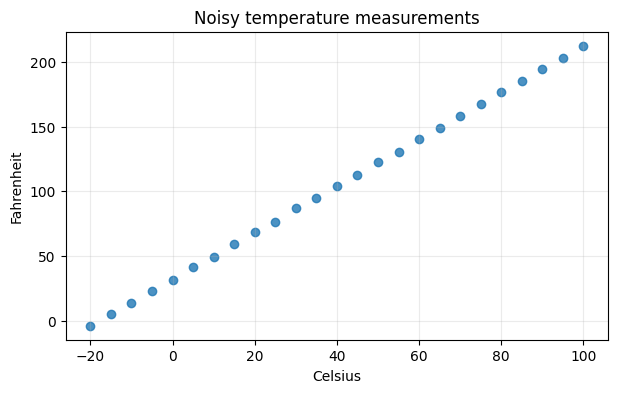

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

DATA_PATH = "sample_data/celsius_fahrenheit_noisy.csv"

# Read the local measurements into a table with Celsius and Fahrenheit columns.
temperature = pd.read_csv(DATA_PATH)
print(temperature.head())

plt.figure(figsize=(7, 4))  # Set the plot width and height in inches.
# Plot each measurement; alpha controls marker transparency.
plt.scatter(temperature["celsius"], temperature["fahrenheit"], alpha=0.8)
plt.xlabel("Celsius")
plt.ylabel("Fahrenheit")
plt.title("Noisy temperature measurements")
plt.grid(alpha=0.25)
plt.show()

### 4.1 Define `X` and `y`, then split

`X` must be a two-dimensional feature table. `y` is the one-dimensional target. The split reserves 20% of the rows for testing.

In [2]:
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

# Double brackets preserve the two-dimensional feature table required by estimators.
X_temp = temperature[["celsius"]]
y_temp = temperature["fahrenheit"]

# Split features and targets together so corresponding rows stay aligned.
X_temp_train, X_temp_test, y_temp_train, y_temp_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.2,  # Reserve 20% of the rows for evaluation.
    random_state=RANDOM_STATE,  # Make the random split reproducible.
)

print(f"Training rows: {len(X_temp_train)}")
print(f"Test rows: {len(X_temp_test)}")

Training rows: 20
Test rows: 5


### 4.2 Data processing and pipeline

`StandardScaler` is included to demonstrate a reusable preprocessing pipeline. Scaling is not essential for this one-feature linear regression, but the same pattern becomes important for distance-based models and neural networks.

In [3]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Chain preprocessing and modelling so both steps learn only from training rows.
temperature_model = make_pipeline(
    StandardScaler(),  # Centre each feature and scale it to unit variance.
    LinearRegression(),  # Fit a linear relationship to the numeric target.
)

temperature_model.fit(X_temp_train, y_temp_train)  # Learn the scaler and regression parameters.
temp_predictions = temperature_model.predict(X_temp_test)  # Apply both steps to unseen rows.

# MAE and RMSE report errors in Fahrenheit; R-squared measures explained variation.
temp_mae = mean_absolute_error(y_temp_test, temp_predictions)
temp_rmse = np.sqrt(mean_squared_error(y_temp_test, temp_predictions))
temp_r2 = r2_score(y_temp_test, temp_predictions)

print(f"MAE: {temp_mae:.2f} °F")
print(f"RMSE: {temp_rmse:.2f} °F")
print(f"R-squared: {temp_r2:.4f}")

MAE: 0.41 °F
RMSE: 0.44 °F
R-squared: 1.0000


### 4.3 Interpret the learnt relationship

Because the input was standardised inside the pipeline, we convert the fitted coefficient back to the original Celsius scale before comparing it with the exact formula.

Learnt formula: Fahrenheit = 1.8032 × Celsius + 31.9800
Prediction for 37 °C: 98.70 °F
Exact value for 37 °C: 98.60 °F


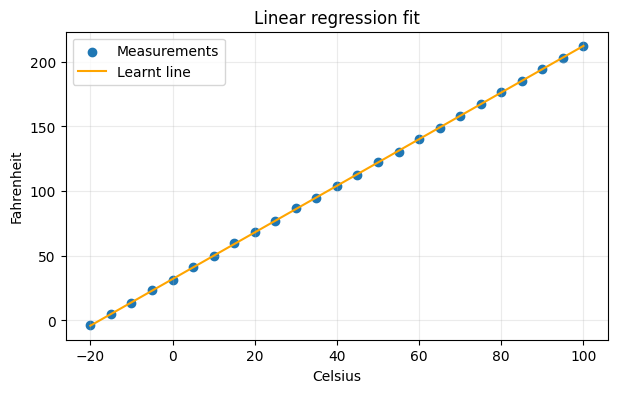

In [4]:
# Access the fitted preprocessing and regression steps by their generated names.
temp_scaler = temperature_model.named_steps["standardscaler"]
temp_regression = temperature_model.named_steps["linearregression"]

# Undo standardisation to express the slope and intercept in Celsius units.
learnt_slope = temp_regression.coef_[0] / temp_scaler.scale_[0]
learnt_intercept = temp_regression.intercept_ - (
    temp_regression.coef_[0] * temp_scaler.mean_[0] / temp_scaler.scale_[0]
)

LINE_POINTS = 100
PREDICTION_CELSIUS = 37
CONVERSION_SLOPE = 1.8
CONVERSION_INTERCEPT = 32

# Create evenly spaced Celsius values to draw the learnt line.
line_x = pd.DataFrame(
    {"celsius": np.linspace(temperature["celsius"].min(), temperature["celsius"].max(), LINE_POINTS)}
)
# Predict Fahrenheit for each point on the line.
line_y = temperature_model.predict(line_x)

new_temperature = pd.DataFrame({"celsius": [PREDICTION_CELSIUS]})
model_prediction = temperature_model.predict(new_temperature)[0]
exact_value = PREDICTION_CELSIUS * CONVERSION_SLOPE + CONVERSION_INTERCEPT

print(f"Learnt formula: Fahrenheit = {learnt_slope:.4f} × Celsius + {learnt_intercept:.4f}")
print(f"Prediction for {PREDICTION_CELSIUS} °C: {model_prediction:.2f} °F")
print(f"Exact value for {PREDICTION_CELSIUS} °C: {exact_value:.2f} °F")

plt.figure(figsize=(7, 4))  # Set the plot dimensions in inches.
plt.scatter(temperature["celsius"], temperature["fahrenheit"], label="Measurements")
# Overlay the fitted line; colour and label distinguish it from the measurements.
plt.plot(line_x["celsius"], line_y, color="orange", label="Learnt line")
plt.xlabel("Celsius")
plt.ylabel("Fahrenheit")
plt.title("Linear regression fit")
plt.grid(alpha=0.25)
plt.legend()
plt.show()

### 4.4 Save the trained pipeline with joblib

Save the fitted scaler and regression model together in `sample_data/temperature_pipeline.joblib`. 

[Official guide: Model persistence](https://scikit-learn.org/stable/model_persistence.html)


In [5]:
import joblib

MODEL_PATH = "sample_data/temperature_pipeline.joblib"

# Save the fitted scaler and regression model together.
joblib.dump(temperature_model, MODEL_PATH)
print(f"Saved trained pipeline to: {MODEL_PATH}")


Saved trained pipeline to: sample_data/temperature_pipeline.joblib


### 4.5 Reload the pipeline and predict

Load the saved pipeline and predict without retraining. This cell can run after a kernel restart, using the same `celsius` feature column. Only load trusted files and use the same Python and package versions as during training.


In [6]:
# Repeat these imports so this cell can also run in a fresh Python session.
import joblib
import pandas as pd

MODEL_PATH = "sample_data/temperature_pipeline.joblib"
# Restore the pipeline we saved, including its learnt parameters.
restored_temperature_model = joblib.load(MODEL_PATH)

# Match the feature name and two-dimensional input used during training.
prediction_inputs = pd.DataFrame({"celsius": [0, 20, 37, 100]})
restored_predictions = restored_temperature_model.predict(prediction_inputs)
prediction_results = prediction_inputs.assign(predicted_fahrenheit=restored_predictions)
print(prediction_results.round(2))


   celsius  predicted_fahrenheit
0        0                 31.98
1       20                 68.04
2       37                 98.70
3      100                212.30


### 4.6 Check that predictions are preserved

After running the earlier training cells, check that both pipelines give the same test predictions within floating-point tolerance.


In [7]:
# Reuse the held-out features to check the save/load round trip.
restored_test_predictions = restored_temperature_model.predict(X_temp_test)
# assert_allclose raises an error if predictions differ beyond these tolerances.
np.testing.assert_allclose(
    restored_test_predictions,
    temp_predictions,
    rtol=1e-10,  # Relative tolerance for each prediction.
    atol=1e-10,  # Absolute tolerance for values near zero.
)
print("Predictions match before and after saving the pipeline.")


Predictions match before and after saving the pipeline.


## 5. Case Study — California Housing Regression

This supervised regression task predicts `median_house_value` from numeric district features. The dataset is imported, cleaned and split once. Each regression model then follows its own complete modelling workflow.

The local CSV describes housing districts. Inputs include location, housing age, room and bedroom totals, population, households and median income. The target is a district's median house value in US dollars. This file includes `ocean_proximity`; the example removes that categorical feature rather than encoding it.

This is the district-level CSV used in the reference case study, rather than the differently prepared table returned by `fetch_california_housing()`.


### 5.1 Data Import and Preparation

The text feature is removed for this introductory comparison, and rows with missing values are dropped. An 80/20 split creates one training set and one unseen test set.


In [8]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
HOUSING_DATA_PATH = "sample_data/california_housing.csv"

# Load the local housing data when it is first used in this case study.
housing_raw = pd.read_csv(HOUSING_DATA_PATH)

# Keep numeric features and remove incomplete rows for this introductory workflow.
housing = housing_raw.drop(columns="ocean_proximity").dropna().reset_index(drop=True)
X_housing = housing.drop(columns="median_house_value")
y_housing = housing["median_house_value"]

# Reserve 20% of rows for an unseen test set; the fixed seed makes the split reproducible.
X_house_train, X_house_test, y_house_train, y_house_test = train_test_split(
    X_housing,
    y_housing,
    test_size=0.2,  # Reserve 20% of rows for unseen evaluation.
    random_state=RANDOM_STATE,  # Reproduce the random split or model initialisation.
)

print(f"Original rows: {len(housing_raw):,}")
print(f"Rows after dropping missing values: {len(housing):,}")
print(f"Training shape: {X_house_train.shape}")
print(f"Test shape: {X_house_test.shape}")
housing.head(3)


Original rows: 20,640
Rows after dropping missing values: 20,433
Training shape: (16346, 8)
Test shape: (4087, 8)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0


### 5.2 Model 1 — Linear Regression

This workflow uses linear regression as an interpretable baseline. Standardisation and the estimator are kept in one pipeline so preprocessing is learnt from the training data only.

**Workflow:** construct → fit → predict → evaluate → inspect.


In [9]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Chain feature standardisation and linear regression in one reusable estimator.
linear_housing_model = make_pipeline(
    StandardScaler(),
    LinearRegression(),
)

# Fit every pipeline step using the housing training partition only.
linear_housing_model.fit(X_house_train, y_house_train)
linear_housing_predictions = linear_housing_model.predict(X_house_test)

# Summarise absolute error, squared error and explained variation on unseen rows.
linear_housing_mae = mean_absolute_error(y_house_test, linear_housing_predictions)
linear_housing_rmse = np.sqrt(mean_squared_error(y_house_test, linear_housing_predictions))
linear_housing_r2 = r2_score(y_house_test, linear_housing_predictions)

print(f"MAE: ${linear_housing_mae:,.0f}")
print(f"RMSE: ${linear_housing_rmse:,.0f}")
print(f"R-squared: {linear_housing_r2:.4f}")


MAE: $51,373
RMSE: $70,156
R-squared: 0.6401


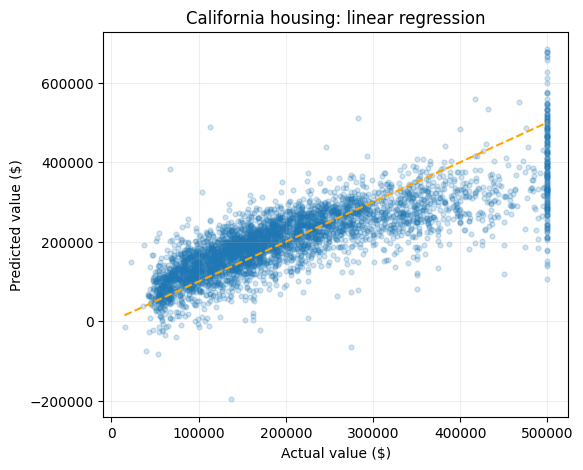

In [10]:
linear_plot_limits = [y_house_test.min(), y_house_test.max()]

# Compare actual and predicted values; the dashed diagonal represents perfect predictions.
plt.figure(figsize=(6, 5))
plt.scatter(y_house_test, linear_housing_predictions, alpha=0.2, s=12)
plt.plot(linear_plot_limits, linear_plot_limits, color="orange", linestyle="--")
plt.xlabel("Actual value ($)")
plt.ylabel("Predicted value ($)")
plt.title("California housing: linear regression")
plt.grid(alpha=0.2)
plt.show()


### 5.3 Model 2 — Multilayer Perceptron Regression

The MLP can learn non-linear relationships. The feature pipeline standardises `X`; `TransformedTargetRegressor` separately standardises `y` during training and converts predictions back to dollars.

**Workflow:** construct → fit → predict → evaluate → inspect.


In [11]:
from sklearn.compose import TransformedTargetRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Build a one-hidden-layer MLP and stop early when validation performance stops improving.
mlp_housing_model = TransformedTargetRegressor(
    regressor=make_pipeline(
        StandardScaler(),
        MLPRegressor(
            hidden_layer_sizes=(32,),  # Use one hidden layer with 32 neurons.
            max_iter=250,  # Cap the number of training passes.
            early_stopping=True,  # Stop when internal validation performance stalls.
            random_state=RANDOM_STATE,  # Reproduce the random split or model initialisation.
        ),
    ),
    transformer=StandardScaler(),
)

# Train this model independently on the housing training partition.
mlp_housing_model.fit(X_house_train, y_house_train)
mlp_housing_predictions = mlp_housing_model.predict(X_house_test)

# Evaluate this model independently on the unseen housing test partition.
mlp_housing_mae = mean_absolute_error(y_house_test, mlp_housing_predictions)
mlp_housing_rmse = np.sqrt(mean_squared_error(y_house_test, mlp_housing_predictions))
mlp_housing_r2 = r2_score(y_house_test, mlp_housing_predictions)

print(f"MAE: ${mlp_housing_mae:,.0f}")
print(f"RMSE: ${mlp_housing_rmse:,.0f}")
print(f"R-squared: {mlp_housing_r2:.4f}")


MAE: $39,754
RMSE: $57,577
R-squared: 0.7576


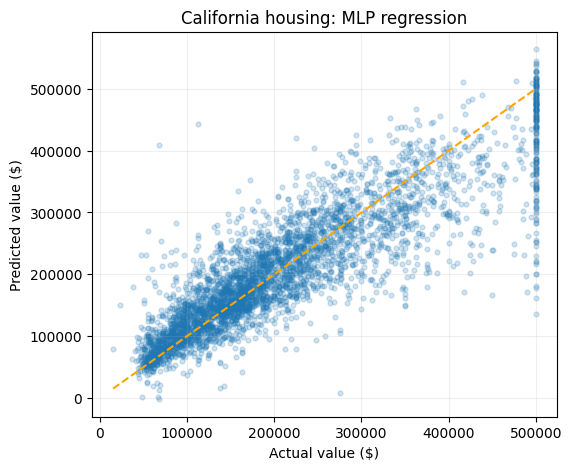

In [12]:
mlp_plot_limits = [y_house_test.min(), y_house_test.max()]

# Inspect the MLP predictions against the same perfect-prediction reference line.
plt.figure(figsize=(6, 5))
plt.scatter(y_house_test, mlp_housing_predictions, alpha=0.2, s=12)
plt.plot(mlp_plot_limits, mlp_plot_limits, color="orange", linestyle="--")
plt.xlabel("Actual value ($)")
plt.ylabel("Predicted value ($)")
plt.title("California housing: MLP regression")
plt.grid(alpha=0.2)
plt.show()


### 5.4 Compare the completed regression workflows

This table compares metrics produced by the two already-completed workflows. It does not rebuild or retrain either model. Lower MAE and RMSE are better; higher R-squared is better.


In [13]:
# Compare stored evaluation results without combining the two training workflows.
housing_results = pd.DataFrame(
    [
        {
            "model": "Linear regression",
            "MAE ($)": linear_housing_mae,
            "RMSE ($)": linear_housing_rmse,
            "R-squared": linear_housing_r2,
        },
        {
            "model": "MLP (one hidden layer)",
            "MAE ($)": mlp_housing_mae,
            "RMSE ($)": mlp_housing_rmse,
            "R-squared": mlp_housing_r2,
        },
    ]
).sort_values("MAE ($)")

housing_results.style.format(
    {"MAE ($)": "${:,.0f}", "RMSE ($)": "${:,.0f}", "R-squared": "{:.4f}"}
)


,model,MAE ($),RMSE ($),R-squared
1,MLP (one hidden layer),"$39,754","$57,577",0.7576
0,Linear regression,"$51,373","$70,156",0.6401


### 5.5 Interpret the Comparison

Compare both models on the same held-out rows. MAE estimates the typical absolute error in dollars, while RMSE gives larger errors more influence. A better result on this split does not establish that a model will generalise to another region or time period.

Dropping incomplete rows is a simple classroom choice that can discard useful data. An extension is to keep those rows and fit a `SimpleImputer` inside each pipeline, using training data only.


## 6. Case Study — MNIST Digit Classification

Each row contains a digit label followed by 784 pixel values for a `28 × 28` greyscale image. Data preparation creates one balanced classroom subset and one stratified train/test split. Two MLP classifiers then follow separate modelling workflows. Their scores use a held-out split of the local training CSV, rather than the official MNIST test set.


### 6.1 Data Import and Preparation

Pixel values are scaled from `0–255` to `0–1`. Stratification preserves approximately the same proportion of each digit in the subset, training set and test set.


In [14]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

MNIST_DATA_PATH = "sample_data/mnist_train_small.csv"
MNIST_SUBSET_SIZE = 3_000
RANDOM_STATE = 42
mnist_columns = ["label"] + [f"pixel_{index}" for index in range(784)]

# Load the local MNIST rows and assign descriptive column names.
mnist = pd.read_csv(MNIST_DATA_PATH, header=None, names=mnist_columns)

# Create a reproducible, stratified subset to keep classroom training times practical.
mnist_subset, _ = train_test_split(
    mnist,
    train_size=MNIST_SUBSET_SIZE,  # Limit the classroom sample to 3,000 rows.
    stratify=mnist["label"],  # Preserve digit proportions in the subset.
    random_state=RANDOM_STATE,  # Reproduce the random split or model initialisation.
)

# Scale pixel intensity to 0–1 and keep labels as integers.
X_digits = mnist_subset.drop(columns="label").to_numpy(dtype=float) / 255.0
y_digits = mnist_subset["label"].to_numpy(dtype=int)

# Reserve a stratified 20% test partition for every independent classifier workflow.
X_digit_train, X_digit_test, y_digit_train, y_digit_test = train_test_split(
    X_digits,
    y_digits,
    test_size=0.2,  # Reserve 20% of rows for unseen evaluation.
    stratify=y_digits,  # Preserve digit proportions in each partition.
    random_state=RANDOM_STATE,  # Reproduce the random split or model initialisation.
)

print(f"Local MNIST rows: {len(mnist):,}")
print(f"Classroom subset: {len(mnist_subset):,}")
print(f"Training shape: {X_digit_train.shape}")
print(f"Test shape: {X_digit_test.shape}")


Local MNIST rows: 6,000
Classroom subset: 3,000
Training shape: (2400, 784)
Test shape: (600, 784)


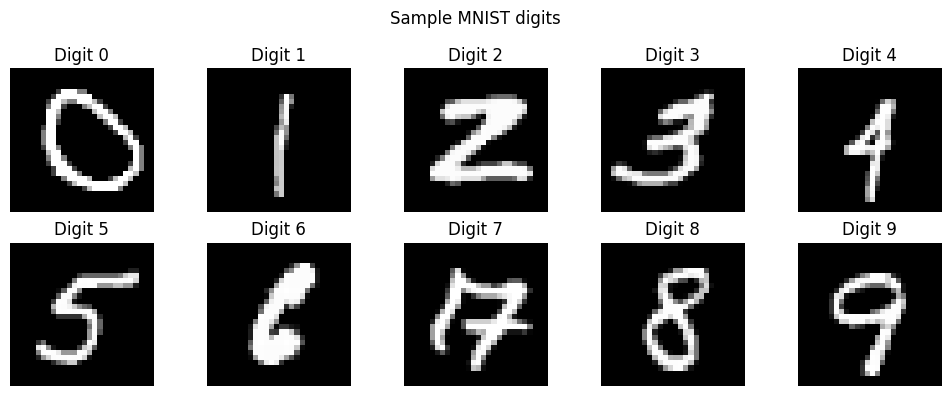

In [15]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))

# Display one prepared example of each digit before modelling.
for digit, axis in enumerate(axes.flat):
    sample_index = np.flatnonzero(y_digits == digit)[0]
    axis.imshow(X_digits[sample_index].reshape(28, 28), cmap="gray")
    axis.set_title(f"Digit {digit}")
    axis.axis("off")

plt.suptitle("Sample MNIST digits")
plt.tight_layout()
plt.show()


### 6.2 Model 1 — MLP with One Hidden Layer

This neural network uses 64 hidden neurons. Early stopping reserves part of the training data as internal validation data and stops when improvement stalls.

**Workflow:** construct → fit → predict → evaluate.


In [16]:
from sklearn.metrics import accuracy_score, f1_score
from sklearn.neural_network import MLPClassifier

# Construct the first classifier with one 64-neuron hidden layer.
digit_mlp_one = MLPClassifier(
    hidden_layer_sizes=(64,),  # Use one hidden layer with 64 neurons.
    max_iter=35,  # Cap training at 35 passes through the training data.
    batch_size=128,  # Update weights using batches of 128 examples.
    early_stopping=True,  # Stop when internal validation performance stalls.
    random_state=RANDOM_STATE,  # Reproduce the random split or model initialisation.
)

# Fit this classifier and predict the held-out digit labels.
digit_mlp_one.fit(X_digit_train, y_digit_train)
digit_mlp_one_predictions = digit_mlp_one.predict(X_digit_test)

# Accuracy measures overall correctness; macro F1 gives each digit equal weight.
mlp_one_accuracy = accuracy_score(y_digit_test, digit_mlp_one_predictions)
mlp_one_f1 = f1_score(y_digit_test, digit_mlp_one_predictions, average="macro")

print(f"Accuracy: {mlp_one_accuracy:.4f}")
print(f"Macro F1: {mlp_one_f1:.4f}")


Accuracy: 0.8967
Macro F1: 0.8966


### 6.3 Model 2 — MLP with Two Hidden Layers

This model adds a second hidden layer. It may represent more complex patterns, but the extra capacity can also increase computation and overfitting risk.

**Workflow:** construct → fit → predict → evaluate.


In [17]:
from sklearn.metrics import accuracy_score, f1_score
from sklearn.neural_network import MLPClassifier

# Construct a separate classifier with 64-neuron and 32-neuron hidden layers.
digit_mlp_two = MLPClassifier(
    hidden_layer_sizes=(64, 32),  # Use two hidden layers with 64 and 32 neurons.
    max_iter=35,  # Cap training at 35 passes through the training data.
    batch_size=128,  # Update weights using batches of 128 examples.
    early_stopping=True,  # Stop when internal validation performance stalls.
    random_state=RANDOM_STATE,  # Reproduce the random split or model initialisation.
)

# Train and predict without reusing the fitted state of the first MLP.
digit_mlp_two.fit(X_digit_train, y_digit_train)
digit_mlp_two_predictions = digit_mlp_two.predict(X_digit_test)

# Evaluate this model's predictions independently.
mlp_two_accuracy = accuracy_score(y_digit_test, digit_mlp_two_predictions)
mlp_two_f1 = f1_score(y_digit_test, digit_mlp_two_predictions, average="macro")

print(f"Accuracy: {mlp_two_accuracy:.4f}")
print(f"Macro F1: {mlp_two_f1:.4f}")


Accuracy: 0.8950
Macro F1: 0.8941


## 7. Case Study — Iris Clustering

**Problem:** Can we discover groups of similar flowers without telling K-means their known species?

The built-in [Iris dataset](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_iris.html) contains 150 flowers, four numeric measurements and three known species. The features are sepal length, sepal width, petal length and petal width, measured in centimetres.


### 7.1 Load and Inspect the Iris Data

Load the built-in dataset as a DataFrame. The four feature columns describe flower measurements; species names identify the known categories, while K-means uses only the measurement columns.

In [18]:
from sklearn.datasets import load_iris

IRIS_RANDOM_STATE = 42

# Return labelled feature columns rather than an unnamed numeric array.
iris = load_iris(as_frame=True)
X_iris = iris.data
known_iris_species = iris.target.map(dict(enumerate(iris.target_names)))

print(f"Samples: {X_iris.shape[0]}")
print(f"Measurement features: {X_iris.shape[1]}")
print(f"Known species held out from K-means: {known_iris_species.nunique()}")
X_iris.head(3)

Samples: 150
Measurement features: 4
Known species held out from K-means: 3


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2


**Select the Number of Clusters:**

When the number of groups is unknown, the **elbow method** plots inertia (within-cluster squared distances) against different values of `k`. Look for a bend where adding more clusters produces a smaller improvement; the bend may not always be clear. See the [scikit-learn guide to K-means and inertia](https://scikit-learn.org/stable/modules/clustering.html#k-means).

This example uses `n_clusters=3` to explore how three discovered groups relate to the three known Iris species. 


### 7.2 Build and Visualise the K-means Model

Standardise all four flower measurements so their different scales contribute comparably to distance calculations. Fit three clusters, then convert their centres back to centimetres for interpretation.

The scatter plot uses petal length and petal width as two original axes. These axes show only part of the information used to fit the clusters.


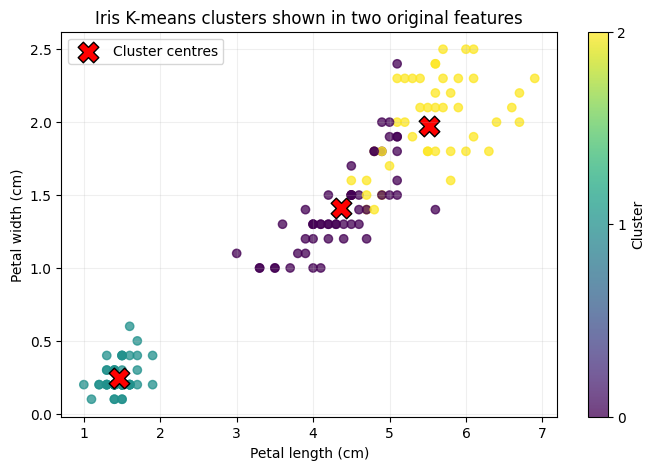

In [19]:
from sklearn.cluster import KMeans

IRIS_INITIALISATIONS = 20

# Standardise the four measurements before calculating distances.
iris_scaler = StandardScaler()
X_iris_scaled = iris_scaler.fit_transform(X_iris)

# Fit three groups using the standardised measurements, without species labels.
iris_cluster_model = KMeans(
    n_clusters=3,  # Form three groups for comparison with the known species.
    n_init=IRIS_INITIALISATIONS,  # Compare repeated centroid initialisations.
    random_state=IRIS_RANDOM_STATE,  # Reproduce the final grouping.
)
iris_clusters = iris_cluster_model.fit_predict(X_iris_scaled)

# Undo standardisation to express each centre in the original centimetre units.
iris_cluster_centres = pd.DataFrame(
    iris_scaler.inverse_transform(iris_cluster_model.cluster_centers_),
    columns=X_iris.columns,
)

plt.figure(figsize=(8, 5))  # Set the figure width and height in inches.
scatter = plt.scatter(
    X_iris["petal length (cm)"],
    X_iris["petal width (cm)"],
    c=iris_clusters,  # Colour observations by their discovered group.
    cmap="viridis",  # Choose the colour scale for cluster IDs.
    alpha=0.75,  # Make overlapping observations easier to see.
)
plt.scatter(
    iris_cluster_centres["petal length (cm)"],
    iris_cluster_centres["petal width (cm)"],
    marker="X",  # Distinguish cluster centres from observations.
    s=220,  # Set the centre marker area.
    c="red",
    edgecolor="black",
    label="Cluster centres",
)
plt.xlabel("Petal length (cm)")
plt.ylabel("Petal width (cm)")
plt.title("Iris K-means clusters shown in two original features")
plt.colorbar(scatter, ticks=range(iris_cluster_model.n_clusters), label="Cluster")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

## 8. Case Study — Product Recommendation

**Problem:** Which products could we recommend to a customer based on purchases by other customers with similar behaviour?

This case uses K-means to group customers without predefined labels. It then ranks products within the target customer's group and excludes items that customer has already purchased. The recommendation is a ranked product list rather than a predicted target column.


### 8.1 Dataset Description and Source

**Kaggle source:** [Online Retail II](https://www.kaggle.com/datasets/tunguz/online-retail-ii)

Online Retail II contains invoice-line transactions from a UK-based, non-store retailer that mainly sells giftware. Many customers are wholesalers. Each row describes one product on one invoice, so a single invoice can contain several rows and products. This structure supports customer–product similarity, shopping-basket association and customer-behaviour analysis.

| Original field | Meaning | Use in this case study |
|---|---|---|
| `Invoice` | transaction or invoice identifier; codes beginning with `C` indicate cancellations | constructs shopping baskets and purchase frequency |
| `StockCode` | product identifier | identifies products for recommendation |
| `Description` | product name | displays readable recommendation results |
| `Quantity` | units recorded on the invoice line | measures purchase volume |
| `InvoiceDate` | transaction date and time | calculates recency |
| `Price` | unit price in pounds sterling | calculates spending and price preference |
| `Customer ID` | customer identifier | constructs customer–product interactions |
| `Country` | customer country | supports geographic analysis |

#### 8.1.1 Dataset preprocessing

The teaching subset was prepared as follows:

- remove rows with missing customer identifiers
- remove cancellations, returns, zero quantities and non-positive prices
- retain 600 customers with the most distinct invoices
- retain 250 products appearing across the most transaction rows
- calculate `sales = quantity × unit_price`
- standardise column names and timestamps

After the customer and product filters intersect, the subset contains **74,611 invoice lines, 8,391 invoices, 598 customers and 250 products**. It is a teaching subset rather than a statistically representative sample of every retail customer. Recommendation results therefore apply only to the retained population and products.

### 8.2 Load and Inspect Transactions

Read the prepared invoice lines and parse purchase timestamps for recency calculations. Build a product-name lookup so recommendations can show readable descriptions.


In [20]:
import pandas as pd

ONLINE_RETAIL_DATA_PATH = "sample_data/online_retail_ii_classroom.csv"

# Load transaction-level purchases and parse the timestamp for recency calculations.
retail = pd.read_csv(
    ONLINE_RETAIL_DATA_PATH,
    parse_dates=["invoice_date"],  # Convert purchase times into datetime values.
)

# Create one stable description lookup for displaying product codes clearly.
product_names = (
    retail.dropna(subset=["description"])
    .drop_duplicates("stock_code")
    .set_index("stock_code")["description"]
)

print(f"Transaction rows: {len(retail):,}")
print(f"Invoices: {retail['invoice_no'].nunique():,}")
print(f"Customers: {retail['customer_id'].nunique():,}")
print(f"Products: {retail['stock_code'].nunique():,}")
retail.head(3)


Transaction rows: 74,611
Invoices: 8,391
Customers: 598
Products: 250


,invoice_no,stock_code,description,quantity,invoice_date,unit_price,customer_id,country,sales
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.3
1,536366,22632,HAND WARMER RED POLKA DOT,6,2010-12-01 08:28:00,1.85,17850,United Kingdom,11.1
2,536366,22633,HAND WARMER UNION JACK,6,2010-12-01 08:28:00,1.85,17850,United Kingdom,11.1


### 8.3 Summarise Behaviour and Fit Customer Clusters

Customers are represented with purchasing behaviour features:

- `recency_days`: days since the most recent purchase
- `frequency`: number of invoices
- `monetary`: total spending
- `average_unit_price`: average product price
- `unique_products`: number of distinct products purchased

K-means creates behavioural groups without using predefined membership labels. Recommendations then come from products popular among other customers in the same cluster.

**Implementation flow:**

```{mermaid}
flowchart TD
    accTitle: Customer-cluster recommendation
    accDescr: Summarise customer behaviour. Then Standardise; fit K-means. Then Find popular products in the customer group. Then Exclude past purchases; recommend.
    A["Summarise customer behaviour"]
    B["Standardise; fit K-means"]
    C["Find popular products in the customer group"]
    D["Exclude past purchases; recommend"]
    A --> B --> C --> D
```

In [21]:
import numpy as np
from sklearn.cluster import KMeans
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

CUSTOMER_CLUSTER_COUNT = 4
RETAIL_RANDOM_STATE = 42
analysis_date = retail["invoice_date"].max() + pd.Timedelta(days=1)

# Aggregate transaction rows into one behavioural record per customer.
customer_features = retail.groupby("customer_id").agg(
    recency_days=("invoice_date", lambda values: (analysis_date - values.max()).days),
    frequency=("invoice_no", "nunique"),
    monetary=("sales", "sum"),
    average_unit_price=("unit_price", "mean"),
    unique_products=("stock_code", "nunique"),
)

cluster_feature_names = [
    "recency_days",
    "frequency",
    "monetary",
    "average_unit_price",
    "unique_products",
]

# Compress skewed non-negative behaviour variables before standardisation.
customer_features_for_clustering = customer_features[cluster_feature_names].copy()
for feature_name in cluster_feature_names:
    customer_features_for_clustering[feature_name] = np.log1p(
        customer_features_for_clustering[feature_name]
    )

# Standardise features so currency and count scales contribute comparably.
customer_cluster_model = make_pipeline(
    StandardScaler(),
    KMeans(
        n_clusters=CUSTOMER_CLUSTER_COUNT,  # Create four customer groups.
        n_init=20,  # Compare 20 centroid initialisations.
        random_state=RETAIL_RANDOM_STATE,  # Reproduce centroid initialisation.
    ),
)
customer_features["cluster"] = customer_cluster_model.fit_predict(
    customer_features_for_clustering
)

# Profile clusters using medians, which are robust to unusually large orders.
customer_cluster_profile = customer_features.groupby("cluster").agg(
    customers=("frequency", "size"),
    median_recency_days=("recency_days", "median"),
    median_frequency=("frequency", "median"),
    median_spending=("monetary", "median"),
    median_unit_price=("average_unit_price", "median"),
    median_unique_products=("unique_products", "median"),
)
customer_cluster_profile.style.format(
    {
        "median_recency_days": "{:.0f}",
        "median_frequency": "{:.0f}",
        "median_spending": "£{:,.0f}",
        "median_unit_price": "£{:.2f}",
        "median_unique_products": "{:.0f}",
    }
)


,customers,median_recency_days,median_frequency,median_spending,median_unit_price,median_unique_products
cluster,,,,,,
0,280,8,11,"£2,004",£2.82,53
1,165,33,8,£964,£2.79,28
2,69,16,9,"£1,394",£5.47,18
3,84,3,25,"£8,559",£2.97,60


### 8.4 Recommend Unpurchased Products from the Cluster

Select a customer near the median spending level for a reproducible example. Count the distinct customers in that cluster who bought each product, rank by popularity, and exclude the target customer's past purchases. Return up to five products.


In [22]:
RECOMMENDATION_COUNT = 5

# Choose a customer near the median spending level for a reproducible demonstration.
target_customer_id = (
    customer_features["monetary"] - customer_features["monetary"].median()
).abs().idxmin()
target_cluster = customer_features.loc[target_customer_id, "cluster"]

# Attach cluster membership to transactions and rank products by customers reached.
retail_with_clusters = retail.merge(
    customer_features[["cluster"]],
    left_on="customer_id",
    right_index=True,
)
cluster_product_popularity = (
    retail_with_clusters[retail_with_clusters["cluster"] == target_cluster]
    .groupby("stock_code")["customer_id"]
    .nunique()
    .sort_values(ascending=False)
)

# Exclude products the target customer has already purchased.
already_purchased = set(
    retail.loc[retail["customer_id"] == target_customer_id, "stock_code"]
)
cluster_recommendation_codes = [
    product_code
    for product_code in cluster_product_popularity.index
    if product_code not in already_purchased
][:RECOMMENDATION_COUNT]
cluster_recommendations = pd.DataFrame(
    {
        "stock_code": cluster_recommendation_codes,
        "description": product_names.reindex(cluster_recommendation_codes).values,
        "customers_in_cluster": cluster_product_popularity.reindex(
            cluster_recommendation_codes
        ).values,
    }
)

print(f"Target customer: {target_customer_id}")
print(f"Behaviour cluster: {target_cluster}")
cluster_recommendations


Target customer: 15514
Behaviour cluster: 0


,stock_code,description,customers_in_cluster
0,85099B,JUMBO BAG RED RETROSPOT,135
1,20725,LUNCH BAG RED RETROSPOT,132
2,85123A,WHITE HANGING HEART T-LIGHT HOLDER,125
3,23203,JUMBO BAG DOILEY PATTERNS,123
4,23209,LUNCH BAG DOILEY PATTERN,121


**Interpretation:** Cluster recommendations are easy to explain but are less personalised than collaborative filtering. Cluster numbers are arbitrary identifiers, not ordered membership levels. Inspect the profile table before giving each group a business-friendly name.